<p align="center">
  <b><font size="6">COVID-19 Data Analysis</font></b><br>
  <i>Global &amp; US County-Level Exploratory + Comparative Analysis (Jan&ndash;Jul 2020)</i>
</p>

**Author's note:** this notebook builds on an earlier beginner EDA pass. This version adds
data-quality auditing, per-capita normalization, correlation testing, an unused dataset
(US county-level data), a SQL analysis layer, and a written business-insights section —
so every chart is backed by an explicit finding, not just a picture.

## 1. Business Problem & Project Overview

**Problem framing:** During the first six months of the COVID-19 pandemic (Jan 22 &ndash; Jul 27, 2020),
decision-makers needed answers to three practical questions:

1. **Where is the outbreak worst right now**, in absolute terms and relative to population?
2. **Is the situation improving or worsening** globally and in specific countries/US states?
3. **What is testing telling us** &mdash; are more cases being found because there's more virus, or because
   there's more testing?

**What this analysis can support:** relative prioritization of attention/resources, spotting regions
whose case counts look low only because of low testing, and identifying whether particular
US states are outliers in death rate (not just case count).

**What this analysis cannot support:** causal claims about *why* a country did better or worse
(policy, healthcare capacity, demographics, and reporting practices all confound the raw numbers),
anything about variants or the later stages of the pandemic (data stops in July 2020), or
individual-level risk (this is all aggregate, not patient-level, data).

**Datasets used (6 total):**

| Dataset | Grain | Rows | Used for |
|---|---|---|---|
| `day_wise.csv` | 1 row per day (global) | 188 | Global trend lines |
| `full_grouped.csv` | 1 row per day per country | 35,156 | Country trend lines, SQL layer |
| `country_wise_latest.csv` | 1 row per country (snapshot) | 187 | Country rankings, region grouping |
| `covid_19_clean_complete.csv` | 1 row per day per country/province | 49,068 | Cross-check / province-level detail |
| `worldometer_data.csv` | 1 row per country (snapshot) | 209 | Population, testing &rarr; per-capita metrics |
| `usa_county_wise.csv` | 1 row per day per US county | 627,920 | **New in this version** &mdash; US state/county deep dive |

The original notebook loaded 5 of these 6 files and never used `usa_county_wise.csv`. That gap
is closed in Section 8.

## 2. Imports & Setup

In [2]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Output folder: {OUTPUT_DIR}")

Output folder: outputs


## 3. Load All Six Datasets (including the previously unused one)

In [3]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Acer\Downloads\COVID-19 Data Analysis & Insights
['COVID19_Data_Analysis.ipynb', 'data', 'outputs', 'sql']


In [4]:
import os

print(os.listdir("data"))

['country_wise_latest.csv', 'covid_19_clean_complete.csv', 'day_wise.csv', 'full_grouped.csv', 'usa_county_wise.csv', 'worldometer_data.csv']


In [ ]:
import pandas as pd

# Load original datasets
clean_complete = pd.read_csv("data/covid_19_clean_complete.csv",parse_dates=["Date"])

country_latest = pd.read_csv("data/country_wise_latest.csv")

day_wise = pd.read_csv("data/day_wise.csv",parse_dates=["Date"])

full_grouped = pd.read_csv("data/full_grouped.csv",parse_dates=["Date"])

usa_county = pd.read_csv("data/usa_county_wise.csv")

worldometer = pd.read_csv("data/worldometer_data.csv")

print("All 6 datasets loaded successfully!")

All 6 datasets loaded successfully!


In [ ]:
import pandas as pd

clean_complete = pd.read_csv("data/covid_19_clean_complete.csv",parse_dates=["Date"])

country_latest = pd.read_csv("data/country_wise_latest.csv")

day_wise = pd.read_csv("data/day_wise.csv",parse_dates=["Date"])

full_grouped = pd.read_csv("data/full_grouped.csv",parse_dates=["Date"])

worldometer = pd.read_csv("data/worldometer_data.csv")

usa_county = pd.read_csv("data/usa_county_wise.csv")

usa_county["Date"] = pd.to_datetime(usa_county["Date"],format="%m/%d/%y")

for name, df in [
    ("clean_complete", clean_complete),
    ("country_latest", country_latest),
    ("day_wise", day_wise),
    ("full_grouped", full_grouped),
    ("worldometer", worldometer),
    ("usa_county", usa_county),
]:
    print(f"{name:16s} shape: {df.shape}")

clean_complete   shape: (49068, 10)
country_latest   shape: (187, 15)
day_wise         shape: (188, 12)
full_grouped     shape: (35156, 10)
worldometer      shape: (209, 16)
usa_county       shape: (627920, 14)


## 4. Data Quality Audit

Before doing any analysis, we check every dataset for the four classic problems: missing
values, duplicate rows, inconsistent naming, and out-of-range values. This step was
essentially absent from the earlier version of this notebook.

In [7]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

audit_rows = []

for name, df in [
    ("clean_complete", clean_complete),
    ("country_latest", country_latest),
    ("day_wise", day_wise),
    ("full_grouped", full_grouped),
    ("worldometer", worldometer),
    ("usa_county", usa_county),
]:
    audit_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": df.duplicated().sum(),
        "total_missing_cells": df.isna().sum().sum()
    })

quality_audit = pd.DataFrame(audit_rows)

quality_audit.to_csv(
    OUTPUT_DIR / "data_quality_audit.csv",
    index=False
)

quality_audit

,dataset,rows,columns,duplicate_rows,total_missing_cells
0,clean_complete,49068,10,0,34404
1,country_latest,187,15,0,0
2,day_wise,188,12,0,0
3,full_grouped,35156,10,0,0
4,worldometer,209,16,0,819
5,usa_county,627920,14,0,3008


**Finding 1 &mdash; country-name mismatches.** `country_latest`/`full_grouped` and `worldometer`
label several countries differently (`US` vs `USA`, `South Korea` vs `S. Korea`, `UK` vs
`United Kingdom`, `Congo (Kinshasa)` vs `DRC`, etc.). A naive merge on country name silently
drops these countries. We build an explicit name-standardization map before any merge.

In [ ]:
COUNTRY_NAME_MAP = {
    "USA": "US",
    "S. Korea": "South Korea",
    "UK": "United Kingdom",
    "UAE": "United Arab Emirates",
    "DRC": "Congo (Kinshasa)",
    "Congo": "Congo (Brazzaville)",
    "CAR": "Central African Republic",
    "Ivory Coast": "Cote d'Ivoire",
    "Myanmar": "Burma",
    "Czech Republic (Czechia)": "Czechia",
    "Taiwan": "Taiwan*",
    "Vatican City": "Holy See",
    "St. Vincent Grenadines": "Saint Vincent and the Grenadines",
    "Palestine": "West Bank and Gaza"
}

worldometer_std = worldometer.copy()

worldometer_std["Country/Region"] = (worldometer_std["Country/Region"].str.strip().replace(COUNTRY_NAME_MAP))

top20 = country_latest.sort_values("Confirmed", ascending=False).head(20)["Country/Region"]

still_missing = sorted(set(top20) - set(worldometer_std["Country/Region"]))

print("Top-20 countries still unmatched:", still_missing)

Top-20 countries still unmatched: []


**Finding 2 &mdash; `Province/State` is missing for 34,404 of 49,068 rows** in
`covid_19_clean_complete.csv`. This is not bad data &mdash; most countries simply aren't split into
provinces &mdash; but leaving it as `NaN` makes later `groupby` calls silently drop those rows if you
group by `Province/State`. We fill it explicitly so that's never a silent trap.

In [9]:
before_missing = clean_complete["Province/State"].isna().sum()
clean_complete["Province/State"] = clean_complete["Province/State"].fillna("Not Reported")
after_missing = clean_complete["Province/State"].isna().sum()
print(f"Province/State missing: {before_missing} -> {after_missing}")

Province/State missing: 34404 -> 0


**Finding 3 &mdash; `worldometer_data.csv` has real holes** in `NewCases`, `NewDeaths`, and
`NewRecovered` (missing for ~205 of 209 countries) &mdash; those columns are not usable and we exclude
them rather than impute fake values. `WHO Region` is also missing for 25 rows in `worldometer`;
for aggregation by region we fill it via the standardized country name using `country_latest` as
the reference (rather than dropping those countries and understating region totals).

In [10]:
wm = worldometer_std.drop(columns=["NewCases", "NewDeaths", "NewRecovered"])
region_lookup = country_latest.set_index("Country/Region")["WHO Region"]
wm["WHO Region"] = wm["WHO Region"].fillna(wm["Country/Region"].map(region_lookup))
print("WHO Region still missing after fill:", wm["WHO Region"].isna().sum())

WHO Region still missing after fill: 22


**Finding 4 &mdash; `usa_county_wise.csv` mixes real US states with cruise ships and
territories** (`Diamond Princess`, `Grand Princess`, `Guam`, `Puerto Rico`, etc.) under the same
`Province_State` field. For a "US states" comparison these need to be separated out explicitly
rather than silently included as if they were states.

In [11]:
NON_STATE_ENTITIES = {
    "Diamond Princess", "Grand Princess", "Guam", "Puerto Rico",
    "Virgin Islands", "American Samoa", "Northern Mariana Islands",
}
all_entities = set(usa_county["Province_State"].unique())
us_states_only = sorted(all_entities - NON_STATE_ENTITIES)
print(f"Entities in file: {len(all_entities)} | Treated as non-state: {len(NON_STATE_ENTITIES)} "
      f"| Real US states/DC kept: {len(us_states_only)}")

Entities in file: 58 | Treated as non-state: 7 | Real US states/DC kept: 51


**Finding 5 &mdash; a subtler, more consequential issue: some states have a large share of
their reported deaths attributed to `Unassigned` or `Out of <State>` pseudo-counties rather than
a real county** (e.g., South Dakota shows 1,004 of 1,126 total deaths, 89%, under `Unassigned`,
with 0 confirmed cases recorded against that same bucket). This isn't a rare glitch &mdash; it
materially affects several states and would silently distort any per-state death-rate ranking if
left in. We quantify it and exclude the worst-affected states from that specific ranking, with a
note, rather than either silently including a distorted number or silently dropping the problem.

In [12]:
latest_all = usa_county[usa_county["Date"] == usa_county["Date"].max()]

is_placeholder = latest_all["Admin2"].eq("Unassigned") | latest_all["Admin2"].astype(str).str.startswith("Out of")

total_deaths_by_state = latest_all.groupby("Province_State")["Deaths"].sum()
placeholder_deaths_by_state = latest_all[is_placeholder].groupby("Province_State")["Deaths"].sum()

placeholder_share = (placeholder_deaths_by_state / total_deaths_by_state * 100).dropna()

STATE_DEATH_DATA_FLAG_THRESHOLD = 30  # % of a state's deaths sitting in Unassigned/Out-of buckets
flagged_states = set(placeholder_share[placeholder_share > STATE_DEATH_DATA_FLAG_THRESHOLD].index)

print(f"States where >{STATE_DEATH_DATA_FLAG_THRESHOLD}% of reported deaths are unattributed to a "
      f"real county (excluded from the death-rate ranking in Section 9):")
print(placeholder_share[placeholder_share > STATE_DEATH_DATA_FLAG_THRESHOLD].round(1).sort_values(ascending=False))

States where >30% of reported deaths are unattributed to a real county (excluded from the death-rate ranking in Section 9):
Province_State
South Dakota    89.2
Alaska          68.7
Vermont         59.1
Kansas          37.2
Idaho           34.5
Name: Deaths, dtype: float64


## 5. Global Trend (with 7-day rolling average)

The original chart plotted raw daily totals. Raw *daily new cases* is noisy (weekend reporting
dips, batch corrections), so we add a 7-day rolling average, which is the standard way public
health dashboards smooth this series to see the real trend instead of day-to-day noise.

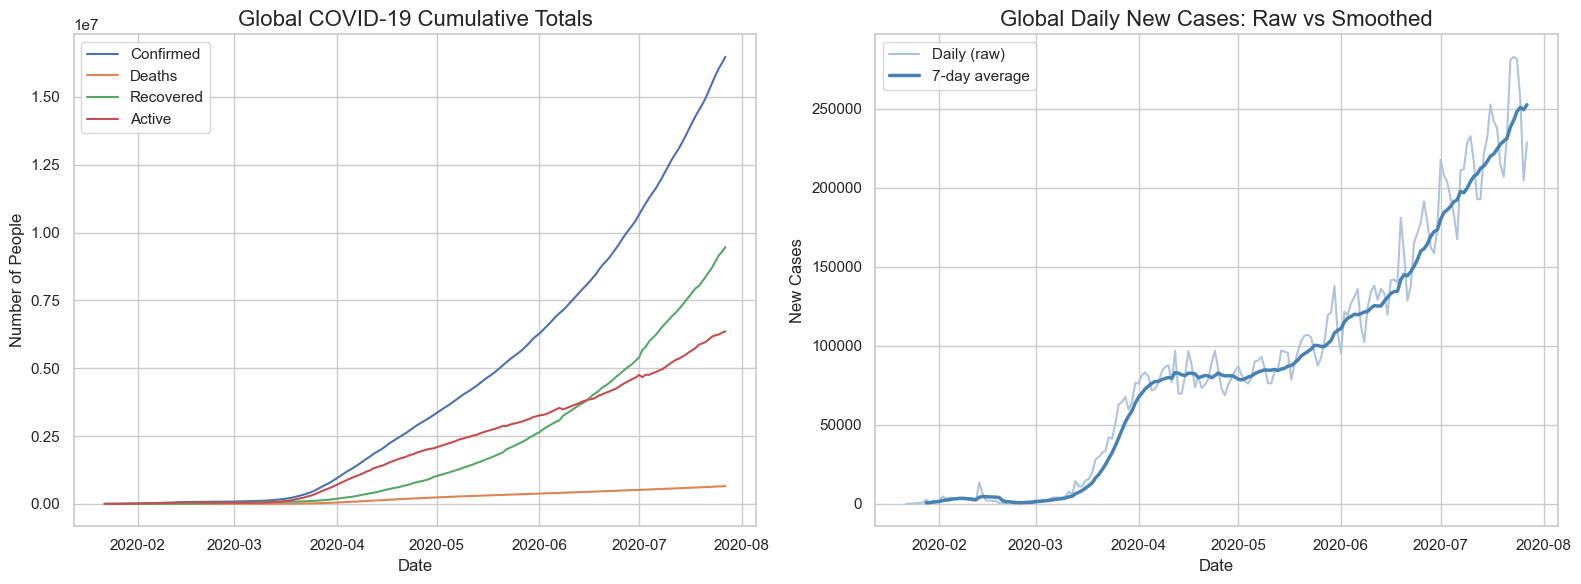

Avg daily new cases, first week of data: 718
Avg daily new cases, last week of data: 252,425
Global totals as of 2020-07-27: 16,480,485 confirmed, 654,036 deaths (3.97% case-fatality rate)


In [13]:
# Create the charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Cumulative totals
for col in ["Confirmed", "Deaths", "Recovered", "Active"]:
    axes[0].plot(day_wise["Date"], day_wise[col], label=col)

axes[0].set_title("Global COVID-19 Cumulative Totals")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Number of People")
axes[0].legend()

# Chart 2: New cases (raw vs 7-day average)
day_wise["New cases (7-day avg)"] = day_wise["New cases"].rolling(7).mean()

axes[1].plot(day_wise["Date"], day_wise["New cases"], color="lightsteelblue", label="Daily (raw)")
axes[1].plot(day_wise["Date"], day_wise["New cases (7-day avg)"], color="steelblue", linewidth=2.5, label="7-day average")

axes[1].set_title("Global Daily New Cases: Raw vs Smoothed")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("New Cases")
axes[1].legend()

# Show and save the charts
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "global_trend_and_new_cases.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculate statistics
first_week_avg = day_wise["New cases"].head(7).mean()
last_week_avg = day_wise["New cases"].tail(7).mean()

total_confirmed = day_wise["Confirmed"].iloc[-1]
total_deaths = day_wise["Deaths"].iloc[-1]
global_cfr = total_deaths / total_confirmed * 100

# Display results
print(f"Avg daily new cases, first week of data: {first_week_avg:,.0f}")
print(f"Avg daily new cases, last week of data: {last_week_avg:,.0f}")
print(
    f"Global totals as of {day_wise['Date'].iloc[-1].date()}: "
    f"{total_confirmed:,} confirmed, "
    f"{total_deaths:,} deaths ({global_cfr:.2f}% case-fatality rate)"
)

## 6. Country Rankings: Raw vs Per-Capita

Raw confirmed-case rankings are dominated by large-population countries almost by definition.
Dividing by population (cases per million people) tells a different, often more decision-relevant,
story about where the outbreak is most *intense*, not just biggest.

Countries matched to population/testing data: 185 of 187


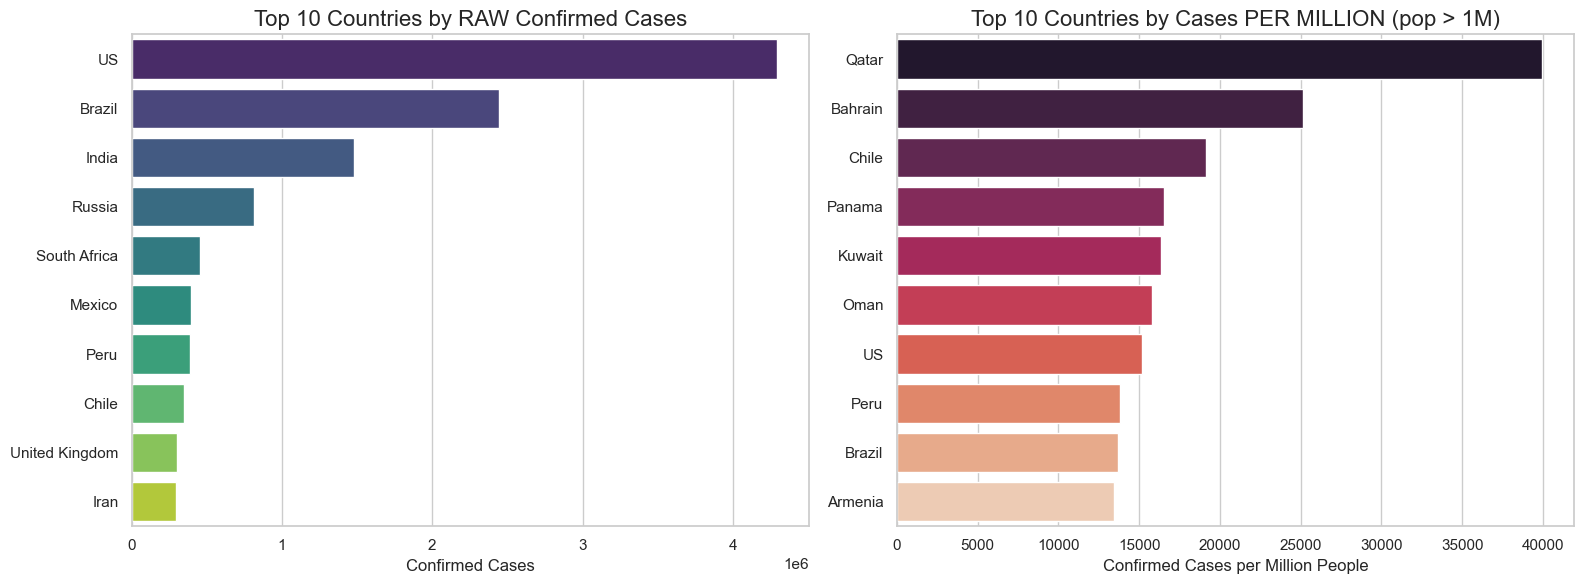

Countries appearing in BOTH top-10 lists: ['Brazil', 'Chile', 'Peru', 'US']
Countries in the per-capita top 10 but NOT the raw top 10: ['Armenia', 'Bahrain', 'Kuwait', 'Oman', 'Panama', 'Qatar']


In [14]:
merged = country_latest.merge(
    wm[["Country/Region", "Population", "Tot Cases/1M pop", "Deaths/1M pop", "Tests/1M pop"]],
    on="Country/Region", how="inner",
)
print(f"Countries matched to population/testing data: {len(merged)} of {len(country_latest)}")

top10_raw = country_latest.sort_values("Confirmed", ascending=False).head(10)[["Country/Region", "Confirmed"]]

# Exclude tiny populations (<1M) so a handful of cases in a small country doesn't dominate the ranking
top10_per_capita = (
    merged[merged["Population"] > 1_000_000]
    .sort_values("Tot Cases/1M pop", ascending=False)
    .head(10)[["Country/Region", "Tot Cases/1M pop", "Confirmed"]]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

chart_configs = [
    (axes[0], top10_raw, "Confirmed", "viridis", "Top 10 Countries by RAW Confirmed Cases", "Confirmed Cases"),
    (axes[1], top10_per_capita, "Tot Cases/1M pop", "rocket", "Top 10 Countries by Cases PER MILLION (pop > 1M)", "Confirmed Cases per Million People"),
]

for ax, data, x_col, palette, title, xlabel in chart_configs:
    sns.barplot(data=data, x=x_col, y="Country/Region", hue="Country/Region",
                palette=palette, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "raw_vs_per_capita_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

overlap = set(top10_raw["Country/Region"]) & set(top10_per_capita["Country/Region"])
print(f"Countries appearing in BOTH top-10 lists: {sorted(overlap)}")
print(f"Countries in the per-capita top 10 but NOT the raw top 10: "
      f"{sorted(set(top10_per_capita['Country/Region']) - set(top10_raw['Country/Region']))}")

## 7. Does More Testing Just Find More Cases? (Correlation Analysis)

A common confound in outbreak data: countries that test more will *report* more confirmed
cases even if the true infection level is similar. We check this directly with a Pearson
correlation between tests-per-million and cases-per-million, plus a scatter plot with a
fitted trend line.

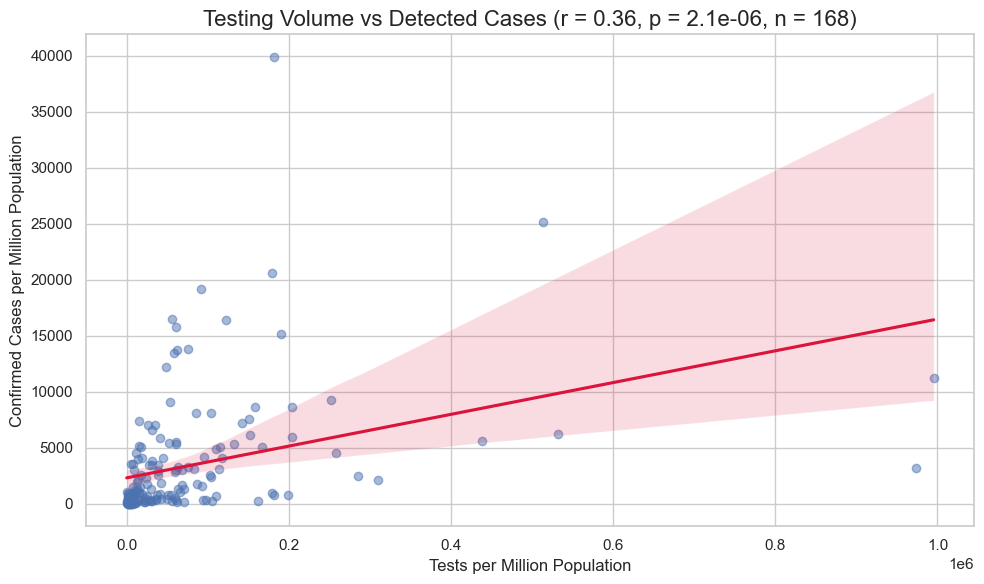

Pearson r = 0.357 (p = 2.10e-06, n = 168 countries)
Interpretation: a positive, statistically significant, but only MODERATE correlation -- testing volume explains some, but far from all, of the variation in reported cases per capita. Raw case counts should not be read as directly comparable across countries with very different testing rates.


In [15]:
test_data = merged.dropna(subset=["Tests/1M pop", "Tot Cases/1M pop"])
r, p_value = stats.pearsonr(test_data["Tests/1M pop"], test_data["Tot Cases/1M pop"])
n = len(test_data)

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=test_data, x="Tests/1M pop", y="Tot Cases/1M pop",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "crimson"}, ax=ax)
ax.set_title(f"Testing Volume vs Detected Cases (r = {r:.2f}, p = {p_value:.1e}, n = {n})")
ax.set_xlabel("Tests per Million Population")
ax.set_ylabel("Confirmed Cases per Million Population")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "testing_vs_cases_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Pearson r = {r:.3f} (p = {p_value:.2e}, n = {n} countries)")
print("Interpretation: a positive, statistically significant, but only MODERATE correlation "
      "-- testing volume explains some, but far from all, of the variation in reported cases per "
      "capita. Raw case counts should not be read as directly comparable across countries with "
      "very different testing rates.")

## 8. WHO Region Comparison: Raw vs Per-Capita

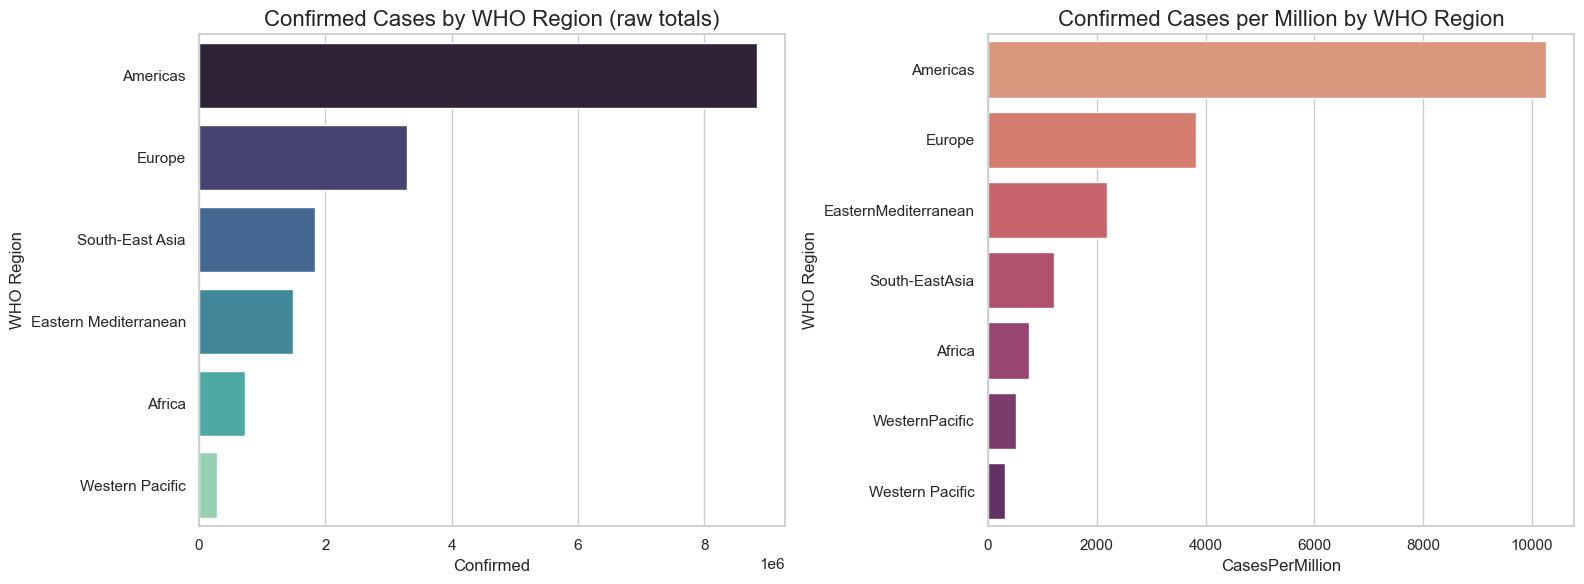

,WHO Region,TotalCases,Population,CasesPerMillion
1,Americas,10452908,1.018990e+09,10258.101724
3,Europe,3544086,9.277339e+08,3820.153701
2,EasternMediterranean,1605866,7.320077e+08,2193.782964
4,South-EastAsia,2426899,1.997513e+09,1214.960548
0,Africa,856646,1.123299e+09,762.616088
6,WesternPacific,267114,5.221449e+08,511.570677
5,Western Pacific,141,4.378930e+05,321.996469


In [16]:
region_summary_raw = (
    country_latest.groupby("WHO Region", as_index=False)[["Confirmed", "Deaths", "Recovered", "Active"]]
    .sum()
    .sort_values("Confirmed", ascending=False)
)

region_pop = wm.groupby("WHO Region", as_index=False).agg(
    TotalCases=("TotalCases", "sum"), Population=("Population", "sum")
)
region_pop["CasesPerMillion"] = region_pop["TotalCases"] / region_pop["Population"] * 1e6
region_pop = region_pop.sort_values("CasesPerMillion", ascending=False)

region_summary_raw.to_csv(OUTPUT_DIR / "region_summary_raw.csv", index=False)
region_pop.to_csv(OUTPUT_DIR / "region_summary_per_capita.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

chart_configs = [
    (axes[0], region_summary_raw, "Confirmed", "mako", "Confirmed Cases by WHO Region (raw totals)"),
    (axes[1], region_pop, "CasesPerMillion", "flare", "Confirmed Cases per Million by WHO Region"),
]

for ax, data, x_col, palette, title in chart_configs:
    sns.barplot(data=data, x=x_col, y="WHO Region", hue="WHO Region",
                palette=palette, legend=False, ax=ax)
    ax.set_title(title)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "region_raw_vs_percapita.png", dpi=150, bbox_inches="tight")
plt.show()

region_pop

**Reading this pair of charts:** the Americas lead on both raw totals and per-capita
intensity, so that ranking is robust. South-East Asia, however, has the second-highest raw case
count but drops to fourth on a per-capita basis (it also has by far the largest regional
population) &mdash; a case where the raw ranking alone would be misleading about relative intensity.

## 9. US State-Level Deep Dive (previously unused dataset)

`usa_county_wise.csv` was uploaded but never used in the earlier version of this project. We
aggregate the 627,920 county-day rows up to state level (excluding cruise ships/territories per
Section 4), then look at both raw totals and, importantly, deaths **relative to confirmed cases**
&mdash; a state with a lower case count can still have a worse outcome ratio.

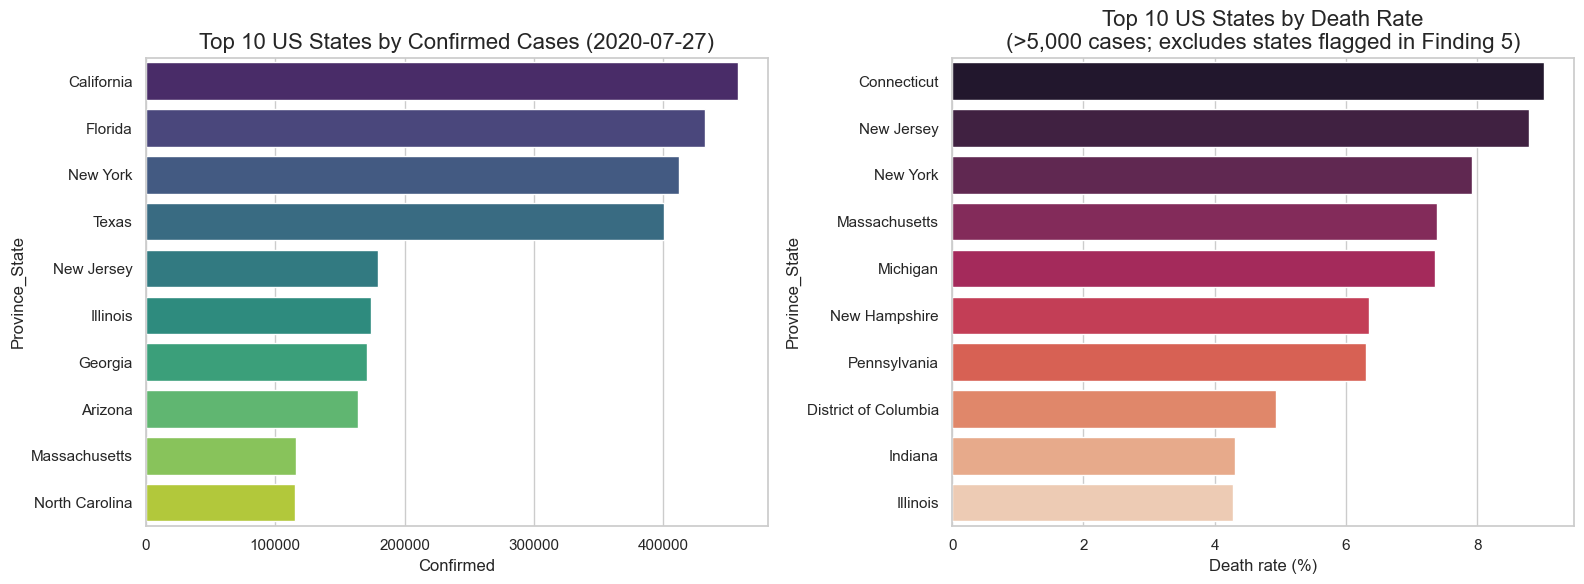

,Province_State,Confirmed,Deaths,Death rate (%)
1315,Connecticut,48983,4418,9.02
5827,New Jersey,179812,15804,8.79
6203,New York,412344,32645,7.92
4135,Massachusetts,115926,8553,7.38
4323,Michigan,87173,6420,7.36
5639,New Hampshire,6441,409,6.35
7331,Pennsylvania,112995,7132,6.31
1691,District of Columbia,11780,581,4.93
2819,Indiana,62907,2709,4.31
2631,Illinois,173894,7417,4.27


In [17]:
usa_states = usa_county[usa_county["Province_State"].isin(us_states_only)]
state_daily = usa_states.groupby(["Province_State", "Date"], as_index=False)[["Confirmed", "Deaths"]].sum()

latest_date = state_daily["Date"].max()
state_latest = state_daily[state_daily["Date"] == latest_date].copy()
state_latest["Death rate (%)"] = (state_latest["Deaths"] / state_latest["Confirmed"] * 100).round(2)
state_latest["Death-data flagged"] = state_latest["Province_State"].isin(flagged_states)
state_latest.to_csv(OUTPUT_DIR / "us_state_summary_latest.csv", index=False)

top10_states_cases = state_latest.sort_values("Confirmed", ascending=False).head(10)

death_rate_eligible = state_latest[(state_latest["Confirmed"] > 5000) & (~state_latest["Death-data flagged"])]
top10_states_deathrate = death_rate_eligible.sort_values("Death rate (%)", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top10_states_cases, x="Confirmed", y="Province_State", hue="Province_State",
            palette="viridis", legend=False, ax=axes[0])
axes[0].set_title(f"Top 10 US States by Confirmed Cases ({latest_date.date()})")

sns.barplot(data=top10_states_deathrate, x="Death rate (%)", y="Province_State", hue="Province_State",
            palette="rocket", legend=False, ax=axes[1])
axes[1].set_title("Top 10 US States by Death Rate\n(>5,000 cases; excludes states flagged in Finding 5)")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "us_state_cases_and_deathrate.png", dpi=150, bbox_inches="tight")
plt.show()

top10_states_deathrate[["Province_State", "Confirmed", "Deaths", "Death rate (%)"]]

**Finding:** with the data-quality-flagged states excluded, Connecticut, New Jersey, and New
York have the highest death rates among high-case-count states in this window &mdash; all three were
hit earliest in the pandemic, before testing capacity and treatment protocols matured elsewhere.
Before excluding the flagged states, South Dakota appeared to have the *highest* death rate of any
state (13.3%) &mdash; but that number was an artifact of 89% of its reported deaths being attributed
to an "Unassigned" county bucket, not a real reflection of outcomes there. This is a concrete
example of why Section 4's audit step matters: skipping it would have put a data-quality artifact
into a business-insight chart as if it were a genuine finding.

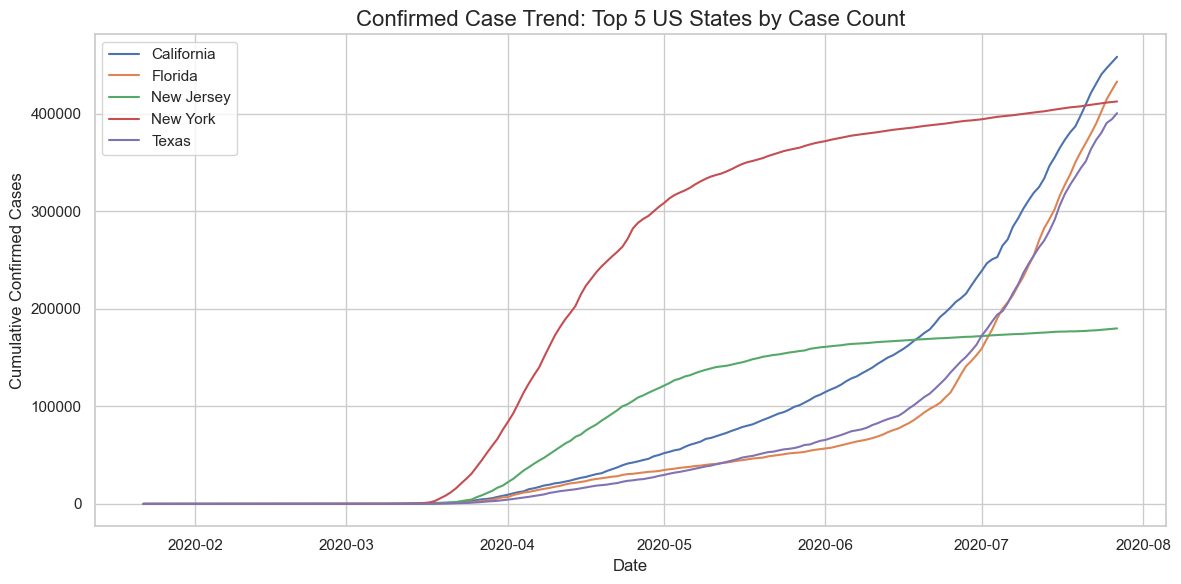

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))

top5_state_names = top10_states_cases["Province_State"].head(5).tolist()
top5_trend = state_daily[state_daily["Province_State"].isin(top5_state_names)].sort_values("Date")

for state, trend in top5_trend.groupby("Province_State"):
    ax.plot(trend["Date"], trend["Confirmed"], label=state)

ax.set_title("Confirmed Case Trend: Top 5 US States by Case Count")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Confirmed Cases")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "us_top5_states_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Reusable Country Trend Function (replaces the hardcoded example)

The earlier version hardcoded `country_name = "India"`. Here it's a function, so any country
can be inspected without editing analysis code &mdash; the kind of change that matters for
maintainability, not just style.

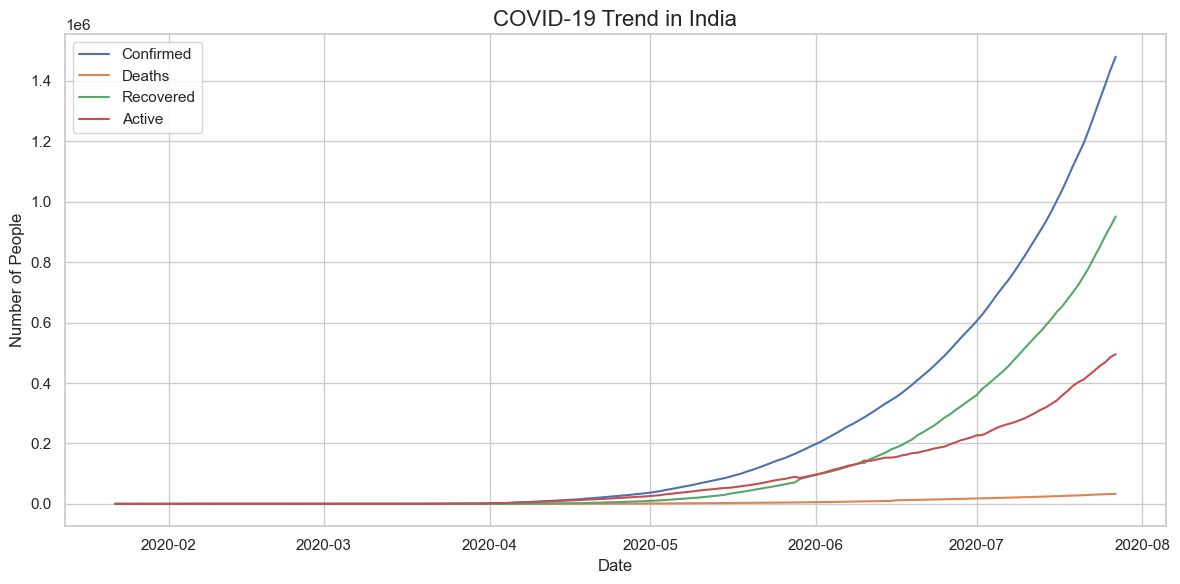

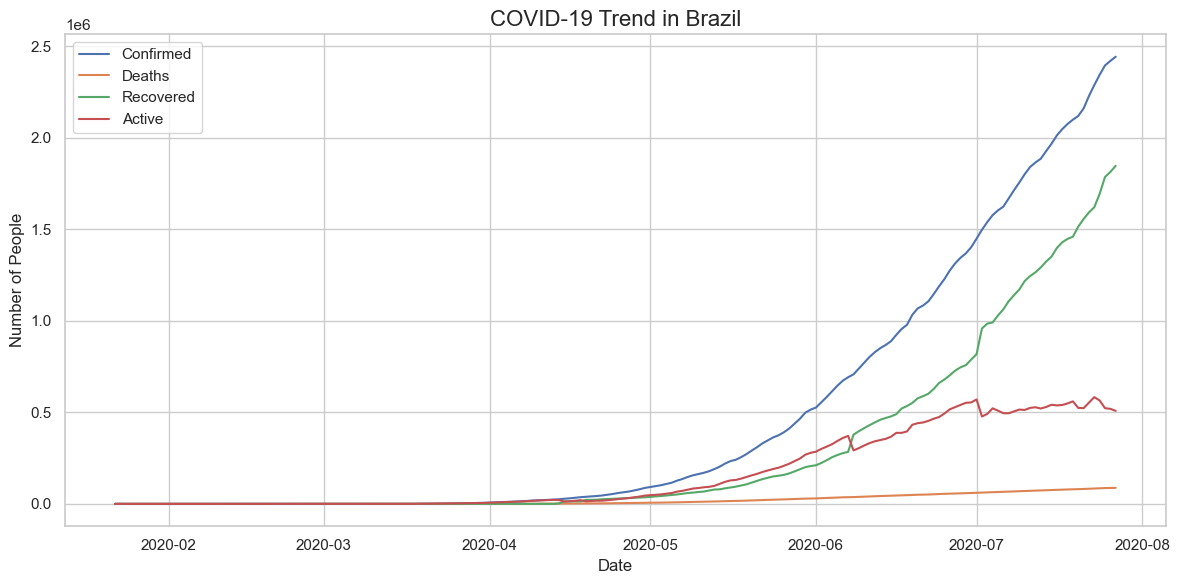

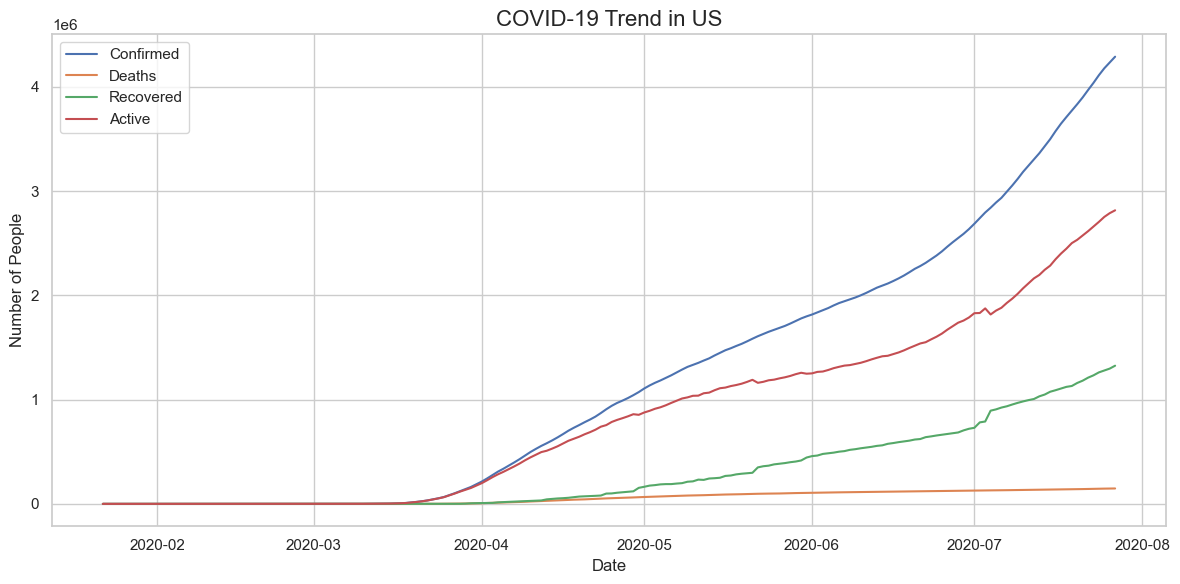

In [19]:
def plot_country_trend(country_name, save=True):
    # Get only the rows for this country
    trend = full_grouped[full_grouped["Country/Region"] == country_name]
    trend = trend.sort_values("Date")

    if len(trend) == 0:
        raise ValueError(f"No rows found for country: {country_name}")

    # Make the chart
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(trend["Date"], trend["Confirmed"], label="Confirmed")
    ax.plot(trend["Date"], trend["Deaths"], label="Deaths")
    ax.plot(trend["Date"], trend["Recovered"], label="Recovered")
    ax.plot(trend["Date"], trend["Active"], label="Active")

    ax.set_title("COVID-19 Trend in " + country_name)
    ax.set_xlabel("Date")
    ax.set_ylabel("Number of People")
    ax.legend()

    fig.tight_layout()

    if save:
        # Turn the country name into a safe filename
        safe_name = country_name.lower()
        safe_name = safe_name.replace(" ", "_")
        safe_name = safe_name.replace("/", "_")
        filename = safe_name + "_covid_trend.png"
        fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")

    plt.show()
    return trend


countries = ["India", "Brazil", "US"]
for c in countries:
    plot_country_trend(c)

## 11. SQL Analysis Layer

The earlier version had no SQL at all. Here we load the key tables into an in-memory SQLite
database and answer the same questions with actual SQL, including a window function &mdash; the
kind of thing worth having ready to walk through in an interview.

In [20]:
conn = sqlite3.connect(":memory:")
full_grouped.to_sql("daily_country", conn, index=False, if_exists="replace")
wm.to_sql("worldometer", conn, index=False, if_exists="replace")

# Q1: Top 5 countries by confirmed cases on the latest date (GROUP BY, subquery, ORDER BY, LIMIT)
q1 = """
SELECT "Country/Region" AS country, Confirmed AS confirmed
FROM daily_country
WHERE Date = (SELECT MAX(Date) FROM daily_country)
ORDER BY confirmed DESC
LIMIT 5;
"""

# Q2: Same ranking, but with population attached and a window-function rank (JOIN + RANK)
q2 = """
SELECT d."Country/Region" AS country,
       d.Confirmed AS confirmed,
       w.Population AS population,
       RANK() OVER (ORDER BY d.Confirmed DESC) AS confirmed_rank
FROM daily_country d
JOIN worldometer w ON d."Country/Region" = w."Country/Region"
WHERE d.Date = (SELECT MAX(Date) FROM daily_country)
ORDER BY confirmed_rank
LIMIT 5;
"""

# Q3: Countries whose case-fatality rate exceeds the global average (CASE, aggregate, HAVING)
q3 = """
SELECT "Country/Region" AS country,
       SUM(Confirmed) AS total_confirmed,
       SUM(Deaths) AS total_deaths,
       ROUND(100.0 * SUM(Deaths) / SUM(Confirmed), 2) AS cfr_pct
FROM daily_country
WHERE Date = (SELECT MAX(Date) FROM daily_country) AND Confirmed > 10000
GROUP BY "Country/Region"
HAVING cfr_pct > 5.0
ORDER BY cfr_pct DESC
LIMIT 10;
"""

queries = [
    ("Q1 - Top 5 countries by confirmed cases (latest date):", q1),
    ("Q2 - Same ranking with population, via JOIN + window function:", q2),
    ("Q3 - Countries (>10k cases) with case-fatality rate above 5%:", q3),
]

for label, query in queries:
    print(label)
    print(pd.read_sql(query, conn), "\n")

Q1 - Top 5 countries by confirmed cases (latest date):
        country  confirmed
0            US    4290259
1        Brazil    2442375
2         India    1480073
3        Russia     816680
4  South Africa     452529 

Q2 - Same ranking with population, via JOIN + window function:
        country  confirmed    population  confirmed_rank
0            US    4290259  3.311981e+08               1
1        Brazil    2442375  2.127107e+08               2
2         India    1480073  1.381345e+09               3
3        Russia     816680  1.459409e+08               4
4  South Africa     452529  5.938157e+07               5 

Q3 - Countries (>10k cases) with case-fatality rate above 5%:
          country  total_confirmed  total_deaths  cfr_pct
0  United Kingdom           301708         45844    15.19
1         Belgium            66428          9822    14.79
2           Italy           246286         35112    14.26
3          France           220352         30212    13.71
4     Netherlands     

Note that Q2's join uses the same standardized `worldometer` table from Section 4 &mdash; before
that fix, `US` would have silently disappeared from this exact query because of the `USA`/`US`
name mismatch. This is a good example of a finding from the cleaning phase directly affecting
the correctness of a later SQL query.

## 12. Business Insights

**Descriptive (what happened):** In this window, the world recorded roughly 16.5 million
confirmed cases and 654,000 deaths, a global case-fatality rate of about 4.0%. The US, Brazil,
and India accounted for the three largest raw case counts.

**Trend (how things changed):** Daily new cases rose from roughly 700/day at the start of the
window to over 250,000/day by the end &mdash; a rise driven mostly by a small number of large
countries rather than a uniform global increase (see Section 9 state trends for one example of
where that growth was concentrated).

**Comparative (raw vs normalized):** Ranking by raw case count and by cases-per-million produces
different top-10 lists (Section 6) &mdash; several smaller countries (e.g., Qatar, Bahrain, Panama)
have far higher case *intensity* than their raw rank suggests. The Americas lead WHO regions on
both measures; South-East Asia's rank drops once population is accounted for (Section 8).

**Testing confound:** Tests-per-million and cases-per-million are positively correlated
(r &asymp; 0.35, p < 0.001) but the relationship is moderate, not strong &mdash; testing volume is a real
but partial explanation for cross-country case differences (Section 7).

**US state-level:** California, Florida, New York, and Texas led on raw case count. Among
high-case states, Connecticut, New Jersey, and New York had the highest death rates once
states with unreliable death attribution were excluded (Section 9) &mdash; consistent with the
Northeast being hit earliest, before testing and treatment approaches had matured elsewhere.
A naive version of this ranking (without the Section 4/9 data-quality check) would have wrongly
put South Dakota in first place due to a reporting artifact, not a real outcome difference.

**What this data cannot tell us:** why any specific country or state performed better or worse
(that requires policy, healthcare-capacity, and demographic data this dataset doesn't have), or
anything about the pandemic's trajectory after July 2020.

## 13. Limitations & Assumptions

- Data covers **Jan 22 &ndash; Jul 27, 2020 only** &mdash; the earliest phase of the pandemic, before
  vaccines, variants, and mature testing infrastructure in most countries.
- Case and death counts depend entirely on **each country's testing and reporting practices**,
  which varied enormously; cross-country comparisons of raw numbers should always be read with
  that caveat (Section 7 quantifies part of this effect).
- The country-name standardization map (Section 4) covers the mismatches affecting the top ~20
  countries by case count; a handful of very small countries/territories may still fail to match
  across datasets.
- US county data excludes population, so all US analysis in Section 9 is in raw counts and
  death-rate-among-confirmed, not per-capita &mdash; a natural next extension would be to bring in a
  US Census county population table.
- `Recovered` figures are widely considered less reliable than `Confirmed`/`Deaths` across public
  COVID datasets from this period (recovery wasn't tracked as consistently as it was for
  fatalities); insights above avoid leaning on `Recovered` for that reason.

## 14. Exporting a Clean Dataset for Power BI

**Honest limitation:** this environment can run Python/SQL but not Power BI Desktop, so this
notebook cannot produce an actual `.pbix` file. What it *can* do &mdash; and what actually matters for
a Power BI build &mdash; is hand off a clean, already-modeled dataset plus a concrete plan, so the
Power BI work is model design, not more data cleaning.

**Star-schema export:**
- `fact_daily_country.csv` &mdash; one row per country per day (Confirmed, Deaths, Recovered, Active, New cases)
- `dim_country.csv` &mdash; one row per country (WHO Region, Population, Tests/1M, standardized name)

**Suggested Power BI build:**
- Relationship: `fact_daily_country[Country/Region]` &rarr; `dim_country[Country/Region]` (many-to-one)
- Measures (DAX): `Total Confirmed = SUM(fact[Confirmed])`,
  `CFR % = DIVIDE(SUM(fact[Deaths]), SUM(fact[Confirmed]))`,
  `Cases per Million = DIVIDE(SUM(fact[Confirmed]), SUM(dim[Population])) * 1000000`,
  `7-day New Cases Avg` using `AVERAGEX` over a rolling date window
- Visuals: a map (bubble size = confirmed), a time-series line chart with a country/region
  slicer, and a matrix table with conditional formatting on CFR %
- Slicers: WHO Region, Date range, Country

In [21]:
fact_daily_country = full_grouped[["Date", "Country/Region", "Confirmed", "Deaths", "Recovered",
                                     "Active", "New cases"]]
dim_country = wm[["Country/Region", "WHO Region", "Population", "Tests/1M pop"]].drop_duplicates()

fact_daily_country.to_csv(OUTPUT_DIR / "fact_daily_country.csv", index=False)
dim_country.to_csv(OUTPUT_DIR / "dim_country.csv", index=False)
print(f"Exported {len(fact_daily_country):,} fact rows and {len(dim_country)} dimension rows to outputs/")

Exported 35,156 fact rows and 209 dimension rows to outputs/


## 15. Final Notes

All charts and CSVs generated by this notebook are saved to `outputs/`. Compared to the earlier
version, this notebook adds: an explicit data-quality audit and fixes (Section 4), per-capita
normalization (Sections 6, 8), a correlation test on the testing confound (Section 7), the
previously unused US county dataset (Section 9), a parameterized country-trend function
(Section 10), a real SQL layer (Section 11), a written insights section grounded in the actual
computed numbers (Section 12), explicit limitations (Section 13), and a concrete, honest plan
for a Power BI layer (Section 14).